# Неделя 03. Городские поездки: от таблицы к проверенному отчёту

**Продолжение практики Titanic · pandas и работа с файлами · Tech Orda**  
**Преподаватель:** Gizatov A. S. / Ғизатов Асылбек Серікұлы.

На прошлой неделе мы знакомились с таблицей пассажиров. Теперь представим, что команда городского сервиса поездок передала нам выгрузку: **что заказывали, где, когда и чем закончилась поездка**. Наша задача — разобраться в данных и собрать понятный отчёт перед любыми моделями AI/ML.

Здесь нет обучения модели. Хорошая модель начинается с понимания строк, пропусков, ключей и метрик. Именно это и потренируем.

**Два связанных файла:** `trips.csv` — заявки на поездки, `zones.json` — названия городских зон. Данные полностью синтетические: это учебная модель сервиса, а не статистика Атырау или другого реального города.

## Как проходить notebook

- Запускайте ячейки сверху вниз: **Shift + Enter**. Один блок кода обычно решает один вопрос.
- Перед запуском попробуйте угадать результат. После запуска объясните его обычными словами.
- Основной маршрут: разделы **0–13**. **14–16** — дополнительные задания, решения и справка.
- Задания не мешают `Run All`: учебные TODO записаны комментариями. Рабочие решения находятся отдельно ниже.
- Файл сохранён с результатами: сначала можно просто читать. Для собственной проверки: **Restart Kernel → Run All**. В Colab: **Runtime → Restart session and run all**.

**Что уже знакомо по Titanic:** `head`, `info`, `describe`, `loc`, условия, `groupby`, пропуски.  
**Что добавим:** смысл индекса, даты, два формата файлов, `merge`, проверка потерь/размножения строк и сохранение отчёта.

Данные встроены в этот `.ipynb`. После установки библиотек для выполнения интернет, GitHub, API-ключи и отдельные файлы не нужны.

### Маршрут двух занятий

Это крупный конспект-практикум, а не требование разобрать каждую строку за одну пару. Теория объясняется отдельно на презентациях, notebook остаётся опорой после занятия.

| Занятие | Теория, 36 минут | Практика, 54 минуты |
|---|---|---|
| 1 | Строка/столбец/индекс, маски, группы, смысл пропуска | 0–3: загрузка и инспекция (15 мин); 4–6: фильтр, новая колонка, сводка (25 мин); 7: график и мини-задача (14 мин) |
| 2 | CSV/JSON, ключ, LEFT/INNER JOIN, проверки и экспорт | 8–9: JSON и merge (20 мин); 10–11: проверка и отчёт (20 мин); 12–13: экспорт и итог (14 мин) |

**Минимум на занятии:** код с преподавателем + остановки «Попробуйте». Тонкости из блока «Если осталось время», 8 самостоятельных задач и бонус оставьте для самостоятельной работы (примерно 60–90 минут).

## 0. Подготовка

Нужны Python 3.10+, pandas, NumPy, matplotlib и среда Jupyter/Colab. В Colab обычно всё уже установлено.

Если импорт ниже пишет `ModuleNotFoundError`, выполните установку в отдельной ячейке, затем перезапустите ядро:

`%pip install pandas==2.2.3 numpy==2.1.3 matplotlib==3.9.2`

NumPy здесь нужен только для простой проверки чисел. Не нужно заново изучать всю библиотеку.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json
from pathlib import Path
from tempfile import mkdtemp
from IPython.display import display

pd.set_option("display.max_columns", 12)
plt.rcParams.update({"figure.figsize": (8, 4), "figure.dpi": 110})
print("pandas:", pd.__version__, "| NumPy:", np.__version__)

pandas: 2.2.3 | NumPy: 2.1.3


### Учебные файлы уже внутри notebook

Следующая служебная ячейка содержит текст двух файлов. **Просто запустите её; переписывать 170 строк данных не нужно.** В Jupyter/Colab её можно свернуть.

Она создаёт новую папку `week03_run_...` рядом с notebook и кладёт туда `data/` и `output/`. Новая папка при каждом полном запуске защищает ваши предыдущие результаты от перезаписи. Свои файлы она не ищет и не меняет.

В настоящем проекте эти файлы пришли бы из базы или системы логирования. Здесь их небольшой снимок включён прямо в учебник, чтобы всё работало офлайн.

In [2]:
# Служебная ячейка: фиксированные синтетические данные, не случайная генерация.
# Код анализа начинается в разделе 1.
TRIPS_CSV = """trip_id,requested_at,zone_id,channel,status,distance_km,duration_min,fare_kzt
1001,2026-10-05 06:00,Z01,app,cancelled,,,
1002,2026-10-05 06:30,Z03,phone,completed,3.0,12.7,1100
1003,2026-10-05 07:00,Z02,app,completed,15.8,56.2,3450
1004,2026-10-05 07:30,Z03,app,completed,11.8,32.6,2650
1005,2026-10-05 08:00,Z01,phone,completed,9.7,28.7,2250
1006,2026-10-05 08:30,Z05,web,completed,15.1,59.4,3150
1007,2026-10-05 09:00,Z04,,completed,10.5,28.7,2450
1008,2026-10-05 09:30,Z04,app,completed,1.6,9.2,800
1009,2026-10-05 10:00,Z01,phone,cancelled,,,
1010,2026-10-05 10:30,Z03,phone,completed,8.6,,2050
1011,2026-10-05 11:00,Z02,app,completed,15.8,53.8,3400
1012,2026-10-05 11:30,Z03,app,completed,5.1,13.5,1500
1013,2026-10-05 12:00,Z03,app,completed,13.6,39.4,2900
1014,2026-10-05 12:30,Z04,app,completed,13.3,47.2,2950
1015,2026-10-05 13:00,Z01,app,completed,18.5,59.1,3900
1016,2026-10-05 13:30,Z02,phone,completed,8.7,25.1,1950
1017,2026-10-05 14:00,Z01,phone,cancelled,,,
1018,2026-10-05 14:30,Z05,phone,cancelled,,,
1019,2026-10-05 15:00,Z05,app,completed,4.7,19.4,1450
1020,2026-10-05 15:30,Z04,phone,completed,10.9,44.6,2450
1021,2026-10-05 16:00,Z02,phone,completed,8.8,35.5,2050
1022,2026-10-05 16:30,Z02,web,completed,17.9,64.8,3650
1023,2026-10-05 17:00,Z04,web,completed,7.6,24.7,1800
1024,2026-10-05 17:30,Z02,app,completed,1.2,11.1,650
1025,2026-10-06 06:00,Z03,app,cancelled,,,
1026,2026-10-06 06:30,Z01,app,completed,10.7,32.5,2400
1027,2026-10-06 07:00,Z01,app,completed,11.3,44.2,2550
1028,2026-10-06 07:30,Z04,web,completed,10.6,32.0,2450
1029,2026-10-06 08:00,Z04,app,completed,2.7,15.9,1100
1030,2026-10-06 08:30,Z04,app,completed,10.0,29.1,2250
1031,2026-10-06 09:00,Z02,web,completed,7.9,23.7,2000
1032,2026-10-06 09:30,Z02,phone,completed,1.6,8.5,750
1033,2026-10-06 10:00,Z02,web,cancelled,,,
1034,2026-10-06 10:30,Z03,app,completed,11.9,32.6,2600
1035,2026-10-06 11:00,Z02,app,cancelled,,,
1036,2026-10-06 11:30,Z03,app,completed,2.4,9.5,900
1037,2026-10-06 12:00,Z01,app,completed,15.7,49.3,3250
1038,2026-10-06 12:30,Z03,app,completed,1.6,8.2,800
1039,2026-10-06 13:00,Z05,app,completed,12.6,32.6,2800
1040,2026-10-06 13:30,Z02,app,completed,6.5,20.2,1700
1041,2026-10-06 14:00,Z05,phone,cancelled,,,
1042,2026-10-06 14:30,Z01,app,completed,10.2,32.8,2350
1043,2026-10-06 15:00,Z04,phone,completed,15.9,45.4,3400
1044,2026-10-06 15:30,Z04,app,completed,14.8,55.7,3050
1045,2026-10-06 16:00,Z02,app,completed,10.9,37.0,2400
1046,2026-10-06 16:30,Z03,app,completed,14.2,50.4,3100
1047,2026-10-06 17:00,Z01,app,completed,3.0,15.0,1000
1048,2026-10-06 17:30,Z01,app,completed,7.4,30.2,1750
1049,2026-10-07 06:00,Z03,app,cancelled,,,
1050,2026-10-07 06:30,Z04,app,completed,6.6,18.3,1700
1051,2026-10-07 07:00,Z04,web,completed,5.6,22.2,1450
1052,2026-10-07 07:30,Z01,app,cancelled,,,
1053,2026-10-07 08:00,Z04,app,completed,17.4,51.2,3700
1054,2026-10-07 08:30,Z03,phone,completed,1.9,10.7,900
1055,2026-10-07 09:00,Z02,,completed,16.4,58.0,3550
1056,2026-10-07 09:30,Z05,app,completed,6.2,22.8,1700
1057,2026-10-07 10:00,Z02,app,cancelled,,,
1058,2026-10-07 10:30,Z04,app,completed,17.8,61.1,3800
1059,2026-10-07 11:00,Z02,app,completed,1.6,8.8,700
1060,2026-10-07 11:30,Z04,app,completed,11.9,28.8,2650
1061,2026-10-07 12:00,Z03,web,completed,6.4,19.9,1650
1062,2026-10-07 12:30,Z02,app,completed,8.5,22.7,2050
1063,2026-10-07 13:00,Z01,phone,completed,10.6,37.9,2350
1064,2026-10-07 13:30,Z01,app,completed,10.6,36.0,2350
1065,2026-10-07 14:00,Z05,app,cancelled,,,
1066,2026-10-07 14:30,Z04,app,completed,12.4,49.0,2700
1067,2026-10-07 15:00,Z02,app,completed,14.1,36.5,3100
1068,2026-10-07 15:30,Z05,app,completed,18.0,62.7,3850
1069,2026-10-07 16:00,Z05,app,cancelled,,,
1070,2026-10-07 16:30,Z05,web,completed,5.2,21.4,1400
1071,2026-10-07 17:00,Z02,app,completed,9.1,37.4,2200
1072,2026-10-07 17:30,Z03,app,completed,12.1,34.5,2650
1073,2026-10-08 06:00,Z04,phone,cancelled,,,
1074,2026-10-08 06:30,Z04,phone,completed,12.3,30.5,2800
1075,2026-10-08 07:00,Z01,phone,completed,2.9,15.2,1100
1076,2026-10-08 07:30,Z03,app,completed,17.7,54.0,3700
1077,2026-10-08 08:00,Z04,app,completed,17.9,,3700
1078,2026-10-08 08:30,Z02,app,completed,1.9,12.3,800
1079,2026-10-08 09:00,Z05,app,completed,6.1,17.8,1700
1080,2026-10-08 09:30,Z03,phone,completed,12.4,47.6,2850
1081,2026-10-08 10:00,Z05,web,cancelled,,,
1082,2026-10-08 10:30,Z05,app,completed,10.1,28.3,2250
1083,2026-10-08 11:00,Z01,app,completed,12.8,46.6,2800
1084,2026-10-08 11:30,Z01,app,completed,10.4,34.3,2300
1085,2026-10-08 12:00,Z05,app,completed,16.3,55.8,3500
1086,2026-10-08 12:30,Z02,app,cancelled,,,
1087,2026-10-08 13:00,Z02,app,completed,10.8,30.0,2450
1088,2026-10-08 13:30,Z05,app,completed,2.4,15.4,1050
1089,2026-10-08 14:00,Z02,phone,cancelled,,,
1090,2026-10-08 14:30,Z01,app,completed,10.0,32.8,2400
1091,2026-10-08 15:00,Z04,app,completed,6.6,20.1,1750
1092,2026-10-08 15:30,Z05,phone,completed,7.3,29.9,1750
1093,2026-10-08 16:00,Z99,phone,completed,12.6,31.4,2700
1094,2026-10-08 16:30,Z02,phone,completed,8.9,25.6,2050
1095,2026-10-08 17:00,Z02,app,completed,14.6,40.9,3200
1096,2026-10-08 17:30,Z02,app,completed,13.6,45.9,3000
1097,2026-10-09 06:00,Z04,app,cancelled,,,
1098,2026-10-09 06:30,Z04,app,completed,15.7,55.7,3350
1099,2026-10-09 07:00,Z02,app,completed,17.2,56.4,3650
1100,2026-10-09 07:30,Z04,app,completed,11.2,40.4,2550
1101,2026-10-09 08:00,Z04,app,completed,1.4,10.3,800
1102,2026-10-09 08:30,Z04,app,completed,1.5,8.2,750
1103,2026-10-09 09:00,Z03,app,cancelled,,,
1104,2026-10-09 09:30,Z03,,completed,14.5,54.7,3050
1105,2026-10-09 10:00,Z05,app,cancelled,,,
1106,2026-10-09 10:30,Z04,phone,completed,2.7,12.3,1050
1107,2026-10-09 11:00,Z03,app,completed,5.9,18.9,1650
1108,2026-10-09 11:30,Z03,app,completed,17.5,54.2,3650
1109,2026-10-09 12:00,Z02,app,completed,5.6,26.1,1400
1110,2026-10-09 12:30,Z04,app,completed,9.5,31.6,2250
1111,2026-10-09 13:00,Z01,app,completed,15.8,45.0,3250
1112,2026-10-09 13:30,Z04,phone,completed,13.8,46.9,3000
1113,2026-10-09 14:00,Z04,app,cancelled,,,
1114,2026-10-09 14:30,Z03,app,completed,10.0,32.3,2300
1115,2026-10-09 15:00,Z04,app,completed,2.6,14.3,1050
1116,2026-10-09 15:30,Z01,web,completed,16.3,50.5,3350
1117,2026-10-09 16:00,Z05,web,completed,1.7,8.6,850
1118,2026-10-09 16:30,Z01,app,completed,16.1,58.5,3350
1119,2026-10-09 17:00,Z03,phone,completed,6.8,28.8,1800
1120,2026-10-09 17:30,Z04,app,cancelled,,,
1121,2026-10-10 06:00,Z03,phone,cancelled,,,
1122,2026-10-10 06:30,Z01,app,completed,15.0,54.6,3250
1123,2026-10-10 07:00,Z04,app,completed,6.4,24.0,1700
1124,2026-10-10 07:30,Z04,app,completed,4.1,19.3,1300
1125,2026-10-10 08:00,Z01,app,completed,9.7,30.0,2200
1126,2026-10-10 08:30,Z03,phone,completed,2.8,13.1,1000
1127,2026-10-10 09:00,Z01,app,completed,9.3,23.6,2250
1128,2026-10-10 09:30,Z04,phone,completed,6.9,19.1,1650
1129,2026-10-10 10:00,Z02,app,cancelled,,,
1130,2026-10-10 10:30,Z04,app,completed,5.1,21.4,1350
1131,2026-10-10 11:00,Z03,phone,completed,13.7,41.6,2900
1132,2026-10-10 11:30,Z05,app,completed,8.8,36.6,2000
1133,2026-10-10 12:00,Z04,app,completed,4.6,18.9,1400
1134,2026-10-10 12:30,Z03,app,completed,4.2,15.8,1250
1135,2026-10-10 13:00,Z01,web,completed,12.4,49.7,2700
1136,2026-10-10 13:30,Z04,app,completed,9.4,29.4,2200
1137,2026-10-10 14:00,Z03,app,cancelled,,,
1138,2026-10-10 14:30,Z04,app,completed,18.0,54.8,3800
1139,2026-10-10 15:00,Z01,app,completed,10.9,42.8,2400
1140,2026-10-10 15:30,Z02,app,completed,15.5,49.2,3200
1141,2026-10-10 16:00,Z04,app,completed,2.6,10.5,1000
1142,2026-10-10 16:30,Z03,app,completed,12.4,40.9,2750
1143,2026-10-10 17:00,Z03,app,completed,6.7,18.0,1650
1144,2026-10-10 17:30,Z03,app,completed,18.0,60.0,3800
1145,2026-10-11 06:00,Z03,phone,cancelled,,,
1146,2026-10-11 06:30,Z04,app,completed,3.9,17.2,1300
1147,2026-10-11 07:00,Z05,app,completed,8.1,30.0,1950
1148,2026-10-11 07:30,Z01,app,completed,4.4,12.8,1300
1149,2026-10-11 08:00,Z03,app,completed,1.5,9.6,700
1150,2026-10-11 08:30,Z03,phone,completed,6.3,25.2,1750
1151,2026-10-11 09:00,Z02,phone,completed,1.7,10.2,850
1152,2026-10-11 09:30,Z01,app,completed,5.0,13.6,1400
1153,2026-10-11 10:00,Z04,phone,cancelled,,,
1154,2026-10-11 10:30,Z04,app,cancelled,,,
1155,2026-10-11 11:00,Z05,app,completed,2.1,9.7,850
1156,2026-10-11 11:30,Z05,app,completed,4.1,17.5,1300
1157,2026-10-11 12:00,Z04,app,completed,16.8,50.6,3600
1158,2026-10-11 12:30,Z02,web,completed,12.1,32.5,2650
1159,2026-10-11 13:00,Z04,web,completed,2.0,10.2,850
1160,2026-10-11 13:30,Z01,app,completed,12.4,37.7,2800
1161,2026-10-11 14:00,Z04,app,cancelled,,,
1162,2026-10-11 14:30,Z03,app,completed,5.3,22.8,1400
1163,2026-10-11 15:00,Z03,app,completed,5.4,15.2,1400
1164,2026-10-11 15:30,Z02,app,completed,4.2,12.7,1350
1165,2026-10-11 16:00,Z02,app,completed,12.4,30.7,2700
1166,2026-10-11 16:30,Z01,phone,completed,18.2,58.0,3750
1167,2026-10-11 17:00,Z04,app,completed,13.2,44.8,2900
1168,2026-10-11 17:30,Z03,app,completed,15.3,39.0,3300
1009,2026-10-05 10:00,Z01,phone,cancelled,,,
1044,2026-10-06 15:30,Z04,app,completed,14.8,55.7,3050
"""
ZONES_JSON = r'''[
  {
    "zone_id": "Z01",
    "zone_name": "Центр",
    "zone_type": "Смешанная"
  },
  {
    "zone_id": "Z02",
    "zone_name": "Университет",
    "zone_type": "Учебная"
  },
  {
    "zone_id": "Z03",
    "zone_name": "Вокзал",
    "zone_type": "Транспортная"
  },
  {
    "zone_id": "Z04",
    "zone_name": "Жилой район",
    "zone_type": "Жилая"
  },
  {
    "zone_id": "Z05",
    "zone_name": "Деловой район",
    "zone_type": "Деловая"
  }
]'''

RUN_DIR = Path(mkdtemp(prefix="week03_run_", dir=Path.cwd()))
DATA_DIR = RUN_DIR / "data"
OUTPUT_DIR = RUN_DIR / "output"
DATA_DIR.mkdir()
OUTPUT_DIR.mkdir()
(DATA_DIR / "trips.csv").write_text(TRIPS_CSV, encoding="utf-8")
(DATA_DIR / "zones.json").write_text(ZONES_JSON, encoding="utf-8")
print("Готовы trips.csv и zones.json.")
print("Рабочая папка:", RUN_DIR.name)

Готовы trips.csv и zones.json.
Рабочая папка: week03_run_2yvjnivn


# Занятие 1. Понимаем одну таблицу

## 1. Читаем CSV и задаём правильный вопрос

**Одна строка должна быть одной заявкой на поездку.** Заявка может завершиться поездкой (`completed`) или отменой (`cancelled`). Поэтому «число строк» и «число состоявшихся поездок» не всегда одно и то же.

В исходном файле намеренно есть две повторные записи. Пока ничего не удаляем: сначала посмотрим.

In [3]:
# read_csv превращает файл с разделителем-запятой в DataFrame.
raw_trips = pd.read_csv(DATA_DIR / "trips.csv")
raw_trips.head()

,trip_id,requested_at,zone_id,channel,status,distance_km,duration_min,fare_kzt
0,1001,2026-10-05 06:00,Z01,app,cancelled,NaN,NaN,NaN
1,1002,2026-10-05 06:30,Z03,phone,completed,3.0,12.7,1100.0
2,1003,2026-10-05 07:00,Z02,app,completed,15.8,56.2,3450.0
3,1004,2026-10-05 07:30,Z03,app,completed,11.8,32.6,2650.0
4,1005,2026-10-05 08:00,Z01,phone,completed,9.7,28.7,2250.0


### Словарь полей

| Столбец | Смысл | На что обратить внимание |
|---|---|---|
| `trip_id` | Идентификатор заявки | Ключ, а не величина для среднего |
| `requested_at` | Время создания заявки | Пока строка; локальное условное время без часового пояса |
| `zone_id` | Код зоны подачи | Название получим из JSON |
| `channel` | `app`, `phone`, `web` | Есть несколько неизвестных значений |
| `status` | `completed` или `cancelled` | Отмена — тоже заявка, но не выполненная поездка |
| `distance_km` | Фактически пройденные километры | Только завершённые поездки |
| `duration_min` | Фактическая длительность | В двух завершённых поездках измерение потеряно |
| `fare_kzt` | Записанная сумма за поездку, ₸ | Только завершённые поездки; без чаевых и дополнительных платежей |

У отменённых заявок нет фактической длительности, дистанции и стоимости. **Пропуск здесь не означает нулевую поездку.**

Для отчёта будем называть сумму `fare_kzt` **суммой оплат**. Это не прибыль: расходов, возвратов и полной бухгалтерской информации у нас нет.

In [4]:
# shape — (число строк, число столбцов).
print("Размер:", raw_trips.shape)
print("Столбцы:", raw_trips.columns.tolist())

Размер: (170, 8)
Столбцы: ['trip_id', 'requested_at', 'zone_id', 'channel', 'status', 'distance_km', 'duration_min', 'fare_kzt']


In [5]:
# Посмотрим на конец и случайные строки, не только на начало файла.
display(raw_trips.tail(3))
display(raw_trips.sample(3, random_state=42))

,trip_id,requested_at,zone_id,channel,status,distance_km,duration_min,fare_kzt
167,1168,2026-10-11 17:30,Z03,app,completed,15.3,39.0,3300.0
168,1009,2026-10-05 10:00,Z01,phone,cancelled,NaN,NaN,NaN
169,1044,2026-10-06 15:30,Z04,app,completed,14.8,55.7,3050.0


,trip_id,requested_at,zone_id,channel,status,distance_km,duration_min,fare_kzt
139,1140,2026-10-10 15:30,Z02,app,completed,15.5,49.2,3200.0
30,1031,2026-10-06 09:00,Z02,web,completed,7.9,23.7,2000.0
119,1120,2026-10-09 17:30,Z04,app,cancelled,NaN,NaN,NaN


**Остановитесь:** почему нельзя сразу сказать «в таблице 170 поездок»? Назовите две причины до следующего раздела.

## 2. Сначала проверяем, затем изменяем

`info()` показывает типы и число заполненных значений. `describe()` описывает числа. Это разные вопросы.

In [6]:
# info сам печатает результат, поэтому print(raw_trips.info()) не нужен.
raw_trips.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 170 entries, 0 to 169
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   trip_id       170 non-null    int64  
 1   requested_at  170 non-null    object 
 2   zone_id       170 non-null    object 
 3   channel       167 non-null    object 
 4   status        170 non-null    object 
 5   distance_km   140 non-null    float64
 6   duration_min  138 non-null    float64
 7   fare_kzt      140 non-null    float64
dtypes: float64(3), int64(1), object(4)
memory usage: 10.8+ KB


In [7]:
# Не вычисляем среднее идентификатора trip_id.
raw_trips[["distance_km", "duration_min", "fare_kzt"]].describe().round(2)

,distance_km,duration_min,fare_kzt
count,140.00,138.00,140.00
mean,9.54,31.94,2224.64
std,5.12,15.92,923.02
min,1.20,8.20,650.00
25%,5.18,18.45,1400.00
50%,10.00,30.35,2250.00
75%,13.62,45.30,2962.50
max,18.50,64.80,3900.00


In [8]:
# isna → True/False; sum считает True как 1.
raw_trips.isna().sum()

trip_id          0
requested_at     0
zone_id          0
channel          3
status           0
distance_km     30
duration_min    32
fare_kzt        30
dtype: int64

### Две одинаковые записи — две заявки?

`duplicated()` без аргументов сравнивает **все поля**. `duplicated("trip_id")` проверяет только ключ.

В этом учебном файле две строки повторены при выгрузке полностью. Их можно убрать. Если у одинакового ID отличаются стоимость или статус, нельзя просто выбрать удобную строку: нужно разбираться в причине.

In [9]:
# keep=False показывает все экземпляры повторяющихся строк.
print("Лишних полных повторов:", raw_trips.duplicated().sum())
raw_trips.loc[raw_trips.duplicated(keep=False)].sort_values("trip_id")

Лишних полных повторов: 2


,trip_id,requested_at,zone_id,channel,status,distance_km,duration_min,fare_kzt
8,1009,2026-10-05 10:00,Z01,phone,cancelled,NaN,NaN,NaN
168,1009,2026-10-05 10:00,Z01,phone,cancelled,NaN,NaN,NaN
43,1044,2026-10-06 15:30,Z04,app,completed,14.8,55.7,3050.0
169,1044,2026-10-06 15:30,Z04,app,completed,14.8,55.7,3050.0


In [10]:
# Исходник raw_trips сохраняем. Работаем с отдельной таблицей trips.
trips = raw_trips.drop_duplicates().copy()
print("До:", len(raw_trips), "| После:", len(trips))
print("Каждый trip_id уникален:", trips["trip_id"].is_unique)

До: 170 | После: 168
Каждый trip_id уникален: True


`assert` — небольшая проверка: если утверждение неверно, выполнение остановится с понятной ошибкой. Это страховка от незаметной порчи отчёта, не способ «подогнать» результат.

In [11]:
assert trips["trip_id"].is_unique, "Один trip_id встретился несколько раз"
assert len(raw_trips) - len(trips) == 2, "Проверьте, какие строки удалены"
print("Проверки повторов пройдены.")

Проверки повторов пройдены.


### Считаем пропуски с понятным знаменателем

Теперь базовая единица — **168 уникальных заявок**, а не исходные строки с повторами. Одна отсутствующая длительность — это одна заявка, а не один отсутствующий символ.

In [12]:
quality = pd.DataFrame({
    "missing_count": trips.isna().sum(),
    "missing_pct": trips.isna().mean() * 100,
})
quality.round(1)

,missing_count,missing_pct
trip_id,0,0.0
requested_at,0,0.0
zone_id,0,0.0
channel,3,1.8
status,0,0.0
distance_km,29,17.3
duration_min,31,18.5
fare_kzt,29,17.3


In [13]:
# size считает заявки, count — известные длительности.
trips.groupby("status").agg(
    requests=("trip_id", "size"),
    known_duration=("duration_min", "count"),
)

,requests,known_duration
status,,
cancelled,29,0
completed,139,137


**Попробуйте:** объясните пропуски в `duration_min` отдельно для отменённых и завершённых заявок. Почему `fillna(0)` исказит среднюю длительность?

Часть синтаксиса `agg` пока новая. Сейчас важен смысл: сравнить число заявок с числом измерений. В разделе 6 разберём запись по частям.

## 3. Столбец, таблица и индекс

- `trips["status"]` — одна `Series`.
- `trips[["trip_id", "status"]]` — `DataFrame` из двух столбцов.
- `iloc` выбирает по **позиции**, начиная с нуля.
- `loc` выбирает по **метке индекса** или условию.

Индекс слева — адрес строки внутри таблицы. Это не обязательно номер заявки.

In [14]:
print(type(trips["status"]).__name__)
print(type(trips[["trip_id", "status"]]).__name__)
trips[["trip_id", "status", "fare_kzt"]].head(4)

Series
DataFrame


,trip_id,status,fare_kzt
0,1001,cancelled,NaN
1,1002,completed,1100.0
2,1003,completed,3450.0
3,1004,completed,2650.0


In [15]:
# Позиции 0, 1, 2; правая граница iloc не включается.
trips.iloc[0:3, 0:5]

,trip_id,requested_at,zone_id,channel,status
0,1001,2026-10-05 06:00,Z01,app,cancelled
1,1002,2026-10-05 06:30,Z03,phone,completed
2,1003,2026-10-05 07:00,Z02,app,completed


In [16]:
# Сделаем trip_id адресом строки в отдельной таблице.
by_id = trips.set_index("trip_id", verify_integrity=True)
by_id.loc[[1002, 1003], ["zone_id", "status", "fare_kzt"]]

,zone_id,status,fare_kzt
trip_id,,,
1002,Z03,completed,1100.0
1003,Z02,completed,3450.0


In [17]:
# Здесь 1002 — метка. А 1 — вторая позиция.
display(by_id.loc[1002, ["status", "fare_kzt"]])
display(by_id.iloc[1][["status", "fare_kzt"]])

status      completed
fare_kzt       1100.0
Name: 1002, dtype: object

status      completed
fare_kzt       1100.0
Name: 1002, dtype: object

**Попробуйте:** найдите заявку `1010` через `loc`. Затем найдите первые две строки через `iloc`. Почему `by_id.iloc[1010]` не означает «найти заявку 1010»?

Основной анализ продолжаем на `trips`, где `trip_id` остался обычным столбцом. Не нужно постоянно менять индекс.

## 4. Фильтры: от вопроса к условию

Сначала формулируем вопрос словами: «Какие заявки завершились поездкой?» Затем строим условие. Булева маска хранит по одному `True` или `False` для каждой строки.

In [18]:
completed_mask = trips["status"] == "completed"
completed_mask.head(8)

0    False
1     True
2     True
3     True
4     True
5     True
6     True
7     True
Name: status, dtype: bool

In [19]:
# Оставляем только строки, где маска равна True.
completed = trips.loc[completed_mask].copy()
print("Завершённых поездок:", len(completed))
completed.head(3)

Завершённых поездок: 139


,trip_id,requested_at,zone_id,channel,status,distance_km,duration_min,fare_kzt
1,1002,2026-10-05 06:30,Z03,phone,completed,3.0,12.7,1100.0
2,1003,2026-10-05 07:00,Z02,app,completed,15.8,56.2,3450.0
3,1004,2026-10-05 07:30,Z03,app,completed,11.8,32.6,2650.0


In [20]:
# И: поездка завершилась И дистанция не меньше 10 км.
long_trips = trips.loc[
    (trips["status"] == "completed") & (trips["distance_km"] >= 10),
    ["trip_id", "distance_km", "duration_min", "fare_kzt"],
]
print("Найдено:", len(long_trips))
long_trips.head()

Найдено: 70


,trip_id,distance_km,duration_min,fare_kzt
2,1003,15.8,56.2,3450.0
3,1004,11.8,32.6,2650.0
5,1006,15.1,59.4,3150.0
6,1007,10.5,28.7,2450.0
10,1011,15.8,53.8,3400.0


Для таблиц используем `&` (И), `|` (ИЛИ), `~` (НЕ). Каждое условие — в скобках. Обычные Python `and`/`or` здесь не подходят.

Если нужно несколько допустимых значений одного поля, `isin` обычно проще, чем длинная цепочка «ИЛИ».

In [21]:
# Выбираем заявки из приложения или с сайта, включая отменённые.
digital_requests = trips.loc[trips["channel"].isin(["app", "web"])]
print("Из app/web:", len(digital_requests))
digital_requests["status"].value_counts()

Из app/web: 131


status
completed    111
cancelled     20
Name: count, dtype: int64

In [22]:
# Пустые значения ищем через isna, а не сравнение с None или np.nan.
missing_duration = completed.loc[
    completed["duration_min"].isna(),
    ["trip_id", "status", "distance_km", "duration_min"],
]
missing_duration

,trip_id,status,distance_km,duration_min
9,1010,completed,8.6,NaN
76,1077,completed,17.9,NaN


In [23]:
# Сортировка меняет порядок результата, а не исходный trips.
completed.sort_values("fare_kzt", ascending=False)[
    ["trip_id", "distance_km", "fare_kzt"]
].head(5)

,trip_id,distance_km,fare_kzt
14,1015,18.5,3900.0
67,1068,18.0,3850.0
57,1058,17.8,3800.0
143,1144,18.0,3800.0
137,1138,18.0,3800.0


**Попробуйте, 3–4 минуты:** отберите завершённые поездки из `app` со стоимостью не меньше 2000 ₸. Выведите ID, дистанцию и стоимость. Посчитайте строки.

Подсказка: начните с `completed`, тогда условие по статусу повторять не нужно.

In [24]:
# Ваш код здесь. Пример структуры:
# selected = completed.loc[(...) & (...), [...]]
# display(selected.head())
# print(len(selected))

## 5. Новые столбцы без циклов

Чтобы перевести минуты в часы, не нужен цикл по строкам: pandas применит деление ко всему столбцу. Для учебных признаков создадим копию, исходный `trips` оставим понятным.

In [25]:
analysis = completed.copy()
analysis["duration_hours"] = analysis["duration_min"] / 60
analysis[["duration_min", "duration_hours"]].head().round(2)

,duration_min,duration_hours
1,12.7,0.21
2,56.2,0.94
3,32.6,0.54
4,28.7,0.48
5,59.4,0.99


In [26]:
# Прежде чем делить на дистанцию, проверим, что она положительная.
assert analysis["distance_km"].gt(0).all(), "Есть нулевая или отрицательная дистанция"
analysis["fare_per_km"] = analysis["fare_kzt"] / analysis["distance_km"]
analysis[["distance_km", "fare_kzt", "fare_per_km"]].head().round(2)

,distance_km,fare_kzt,fare_per_km
1,3.0,1100.0,366.67
2,15.8,3450.0,218.35
3,11.8,2650.0,224.58
4,9.7,2250.0,231.96
5,15.1,3150.0,208.61


**Как читать `fare_per_km`:** это записанная сумма оплаты, делённая на дистанцию конкретной поездки. Это не доказанная ставка тарифа: в сумме может быть фиксированная часть. Короткая поездка поэтому может быть дороже «за километр».

Пропуск длительности при делении остаётся пропуском. Мы не восстанавливаем неизвестное измерение арифметикой.

## 6. groupby: один вопрос для каждой группы

Представьте три шага:
1. Разделить заявки по каналу заказа.
2. В каждой группе посчитать нужный показатель.
3. Получить маленькую итоговую таблицу.

Начнём с одного показателя.

In [27]:
# dropna=False оставляет неизвестный канал отдельной группой.
requests_by_channel = trips.groupby("channel", dropna=False).size()
requests_by_channel

channel
app      116
phone     34
web       15
NaN        3
dtype: int64

In [28]:
# normalize=True делит количество на число заявок.
(trips["status"].value_counts(normalize=True) * 100).round(1)

status
completed    82.7
cancelled    17.3
Name: proportion, dtype: float64

У доли обязательно есть знаменатель. Здесь это **все уникальные заявки**. Доля отмен в приложении имела бы другой знаменатель: только заявки из приложения.

Теперь несколько метрик сразу. В `agg` запись `requests=("trip_id", "size")` читается так: «создай столбец requests и посчитай строки группы».

In [29]:
channel_summary = trips.groupby("channel", dropna=False).agg(
    requests=("trip_id", "size"),
    known_duration=("duration_min", "count"),
    median_duration_min=("duration_min", "median"),
)
channel_summary.round(1)

,requests,known_duration,median_duration_min
channel,,,
app,116,97,31.6
phone,34,24,28.8
web,15,13,24.7
NaN,3,3,54.7


`size` считает все заявки, `count` — только известные значения выбранного столбца. Медиана пропускает отсутствующие значения.

В таблице выше `requests` включает отмены, а медиана длительности описывает только известные длительности выполненных поездок. Поэтому рядом оставлено число измерений. Для денежного отчёта явно отберём завершённые поездки.

In [30]:
completed_by_zone = completed.groupby("zone_id").agg(
    completed_trips=("trip_id", "size"),
    payments_kzt=("fare_kzt", "sum"),
    median_fare_kzt=("fare_kzt", "median"),
)
completed_by_zone.sort_values("payments_kzt", ascending=False)

,completed_trips,payments_kzt,median_fare_kzt
zone_id,,,
Z04,39,84800.0,2250.0
Z01,26,64750.0,2400.0
Z03,30,63700.0,1925.0
Z02,27,60900.0,2200.0
Z05,16,31550.0,1725.0
Z99,1,2700.0,2700.0


In [31]:
# После группировки сумма должна остаться той же.
assert completed_by_zone["completed_trips"].sum() == len(completed)
assert np.isclose(completed_by_zone["payments_kzt"].sum(), completed["fare_kzt"].sum())
print("Группы не потеряли поездки и суммы.")

Группы не потеряли поездки и суммы.


### Что пока нельзя утверждать

Большая сумма оплат в зоне не означает большую прибыль или лучшее качество сервиса. Возможно, там просто больше поездок или они длиннее. Сравнивайте показатель вместе с количеством наблюдений.

**Попробуйте:** в сводку по зонам добавьте медианную дистанцию. Затем объясните, почему средняя стоимость и общая сумма отвечают на разные вопросы.

## 7. Первый график: сколько заявок пришло из каждого канала?

Столбчатая диаграмма сравнивает категории. Сначала готовим маленькую таблицу, затем рисуем её. Неизвестный канал оставим видимым.

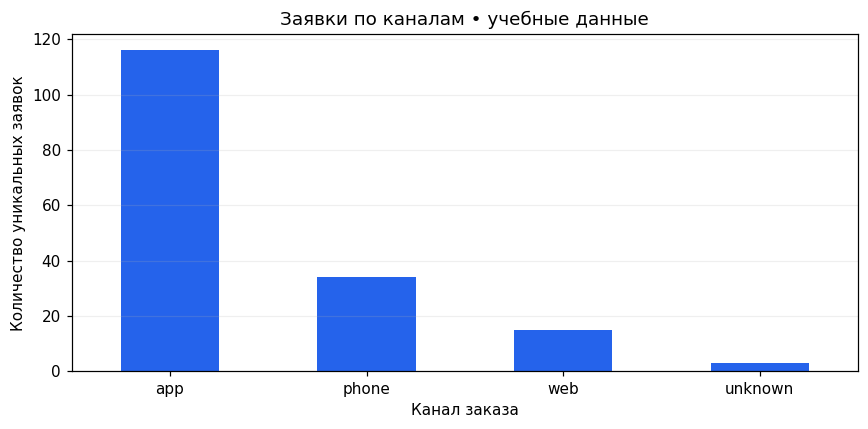

In [32]:
channel_counts = trips["channel"].fillna("unknown").value_counts()
ax = channel_counts.plot.bar(color="#2563EB", rot=0)
ax.set_title("Заявки по каналам • учебные данные")
ax.set_xlabel("Канал заказа")
ax.set_ylabel("Количество уникальных заявок")
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

**Скажите вслух:** что здесь считается, какой канал встречается чаще, где видны пропуски? Почему по высоте столбца нельзя судить о качестве приложения?

**Контрольная точка занятия 1:** вы можете загрузить таблицу, сохранить исходник, убрать доказанные повторы, выбрать строки и построить сводку. На следующем занятии к кодам зон добавим смысл из второго файла.

# Занятие 2. Соединяем файлы и сохраняем результат

Если открыли notebook заново, выполните ячейки сверху до этого места. Не нужно вручную восстанавливать переменные из памяти.

## 8. CSV, даты и JSON

CSV хранит прямоугольную таблицу текстом. Название столбца `requested_at` само по себе не превращает строку в дату.

Научимся явно преобразовывать время и получать из него день и час.

In [33]:
print("Тип до:", trips["requested_at"].dtype)
trips["requested_at"] = pd.to_datetime(
    trips["requested_at"], format="%Y-%m-%d %H:%M", errors="raise"
)
print("Тип после:", trips["requested_at"].dtype)

Тип до: object
Тип после: datetime64[ns]


Формат `%Y-%m-%d %H:%M` означает «год-месяц-день часы:минуты». `errors="raise"` остановит код, если строка не соответствует формату, вместо незаметной потери даты.

На следующих выгрузках можно читать дату сразу: `pd.read_csv(..., parse_dates=["requested_at"])`. Здесь разделяем два шага, чтобы увидеть изменение типа.

In [34]:
trips["request_date"] = trips["requested_at"].dt.date
trips["request_hour"] = trips["requested_at"].dt.hour
trips[["trip_id", "requested_at", "request_date", "request_hour"]].head()

,trip_id,requested_at,request_date,request_hour
0,1001,2026-10-05 06:00:00,2026-10-05,6
1,1002,2026-10-05 06:30:00,2026-10-05,6
2,1003,2026-10-05 07:00:00,2026-10-05,7
3,1004,2026-10-05 07:30:00,2026-10-05,7
4,1005,2026-10-05 08:00:00,2026-10-05,8


### Как выглядит JSON-справочник

JSON может хранить список объектов. Здесь один объект описывает одну зону; ключ `zone_id` должен быть уникальным.

Не нужно учить новый язык: в Python список объектов читается как список словарей.

In [35]:
with (DATA_DIR / "zones.json").open(encoding="utf-8") as file:
    zone_records = json.load(file)

print(type(zone_records).__name__)
zone_records[0]

list


{'zone_id': 'Z01', 'zone_name': 'Центр', 'zone_type': 'Смешанная'}

In [36]:
# Из списка словарей получаем привычную таблицу.
zones = pd.DataFrame(zone_records)
zones

,zone_id,zone_name,zone_type
0,Z01,Центр,Смешанная
1,Z02,Университет,Учебная
2,Z03,Вокзал,Транспортная
3,Z04,Жилой район,Жилая
4,Z05,Деловой район,Деловая


In [37]:
print("Заявок:", len(trips), "| Зон в справочнике:", len(zones))
print("Ключ зон уникален:", zones["zone_id"].is_unique)
assert zones["zone_id"].notna().all(), "В справочнике пустой ключ"
assert zones["zone_id"].is_unique, "В справочнике повторяется ключ"

Заявок: 168 | Зон в справочнике: 5
Ключ зон уникален: True


**Попробуйте:** почему `zone_id` повторяется в заявках, но не должен повторяться в справочнике? Можно ли объединять по порядку строк: первая заявка с первой зоной?

## 9. merge: добавляем названия зон по ключу

У нас отношение **многие к одному**: много заявок могут приходить из одной зоны.

- `on="zone_id"` — ищем совпадение по коду зоны.
- `how="left"` — сохраняем каждую заявку из левой таблицы.
- `validate="many_to_one"` — проверяем, что справа код не повторяется.
- `indicator=True` — добавляем служебный столбец с результатом поиска пары.

Это тот же смысл, который позже появится в SQL JOIN. Сейчас важнее понимать строки, чем запоминать все параметры.

In [38]:
joined = trips.merge(
    zones,
    on="zone_id",
    how="left",
    validate="many_to_one",
    indicator=True,
)
joined[["trip_id", "zone_id", "zone_name", "status", "_merge"]].head()

,trip_id,zone_id,zone_name,status,_merge
0,1001,Z01,Центр,cancelled,both
1,1002,Z03,Вокзал,completed,both
2,1003,Z02,Университет,completed,both
3,1004,Z03,Вокзал,completed,both
4,1005,Z01,Центр,completed,both


In [39]:
# both — пара найдена; left_only — заявку сохранили, но зоны нет.
joined["_merge"].value_counts()

_merge
both          167
left_only       1
right_only      0
Name: count, dtype: int64

In [40]:
unmatched = joined.loc[
    joined["_merge"] == "left_only",
    ["trip_id", "zone_id", "zone_name", "status", "fare_kzt"],
]
unmatched

,trip_id,zone_id,zone_name,status,fare_kzt
92,1093,Z99,NaN,completed,2700.0


В справочнике намеренно отсутствует `Z99`. Мы не придумываем название района и не удаляем заявку: её сумма известна, неизвестна только подпись зоны.

Для отчёта создадим отдельную подпись «Неизвестная зона». Исходный `zone_name` оставим без изменения, чтобы проблема была видна.

In [41]:
joined["zone_report"] = joined["zone_name"].fillna("Неизвестная зона")
joined.loc[joined["_merge"] == "left_only", ["trip_id", "zone_id", "zone_report"]]

,trip_id,zone_id,zone_report
92,1093,Z99,Неизвестная зона


## 10. Проверяем объединение

Правильный на вид результат может быть неправильным по числу строк. Минимальная страховка:
1. число заявок не изменилось;
2. каждый ID по-прежнему уникален;
3. сумма оплат не изменилась.

In [42]:
assert len(joined) == len(trips), "merge изменил число заявок"
assert joined["trip_id"].is_unique, "После merge размножились ID"
assert np.isclose(joined["fare_kzt"].sum(), trips["fare_kzt"].sum())
print("Строки, ключи и сумма сохранены.")

Строки, ключи и сумма сохранены.


### Если осталось время: LEFT и INNER на одном примере

`inner` оставляет только совпавшие ключи. Это полезно для некоторых задач, но здесь незаметно исключит заявку с неизвестной зоной. Сравним числа, а не внешний вид таблицы.

In [43]:
inner_joined = trips.merge(zones, on="zone_id", how="inner", validate="many_to_one")
print("Заявок в LEFT:", len(joined))
print("Заявок в INNER:", len(inner_joined))
print("Потерянная сумма, ₸:", joined["fare_kzt"].sum() - inner_joined["fare_kzt"].sum())

Заявок в LEFT: 168
Заявок в INNER: 167
Потерянная сумма, ₸: 2700.0


### Если осталось время: почему нужен validate

Если у одного кода справа две записи, одна заявка превращается в две строки. Проверка должна остановить расчёт до того, как мы посчитаем завышенные суммы.

Следующая ячейка намеренно портит **отдельную копию** справочника. Ожидаемая ошибка перехватывается, поэтому `Run All` продолжится. Учить `try/except` здесь не обязательно.

In [44]:
bad_zones = pd.concat([zones, zones.iloc[[0]]], ignore_index=True)
try:
    trips.merge(bad_zones, on="zone_id", how="left", validate="many_to_one")
except pd.errors.MergeError:
    print("Проверка сработала: в правой таблице один zone_id встречается дважды.")

Проверка сработала: в правой таблице один zone_id встречается дважды.


## 11. Собираем отчёт по зонам

Пользователь отчёта хочет знать:
- сколько было заявок;
- сколько завершилось поездкой;
- какова доля отмен;
- сколько составили оплаты;
- какова типичная длительность известной выполненной поездки.

Сначала создадим флаги. Булево `True` при суммировании считается как 1.

In [45]:
joined["is_completed"] = joined["status"] == "completed"
joined["is_cancelled"] = joined["status"] == "cancelled"
joined[["trip_id", "status", "is_completed", "is_cancelled"]].head()

,trip_id,status,is_completed,is_cancelled
0,1001,cancelled,False,True
1,1002,completed,True,False
2,1003,completed,True,False
3,1004,completed,True,False
4,1005,completed,True,False


В нашей учебной схеме есть ровно два статуса, а у отменённых заявок сумма оплаты отсутствует. Проверим это перед отчётом. В настоящем сервисе могут быть возвраты, платные отмены и незавершённые заявки, тогда правило расчёта понадобится другое.

In [46]:
assert set(joined["status"].unique()) == {"completed", "cancelled"}
assert joined.loc[joined["is_cancelled"], "fare_kzt"].isna().all()
assert joined.loc[joined["is_completed"], "fare_kzt"].notna().all()
print("Правила учебной схемы подтверждены.")

Правила учебной схемы подтверждены.


In [47]:
zone_report = joined.groupby("zone_report", as_index=False).agg(
    requests=("trip_id", "size"),
    completed_trips=("is_completed", "sum"),
    cancelled_requests=("is_cancelled", "sum"),
    payments_kzt=("fare_kzt", "sum"),
    known_duration=("duration_min", "count"),
    median_duration_min=("duration_min", "median"),
)
zone_report["cancel_pct"] = zone_report["cancelled_requests"] / zone_report["requests"] * 100
zone_report.round(1)

,zone_report,requests,completed_trips,cancelled_requests,payments_kzt,known_duration,median_duration_min,cancel_pct
0,Вокзал,36,30,6,63700.0,29,28.8,16.7
1,Деловой район,22,16,6,31550.0,16,25.6,27.3
2,Жилой район,46,39,7,84800.0,38,28.8,15.2
3,Неизвестная зона,1,1,0,2700.0,1,31.4,0.0
4,Университет,33,27,6,60900.0,27,30.7,18.2
5,Центр,30,26,4,64750.0,26,36.8,13.3


`as_index=False` оставляет название зоны обычным столбцом, что удобно для сохранения файла.

**Знаменатели:**
- `cancel_pct`: отмены / все заявки этой зоны;
- `median_duration_min`: только известные длительности завершённых поездок;
- `payments_kzt`: сумма известных оплат, а не средняя цена и не прибыль.

`sum()` пропускает отсутствующие значения. В наших данных у каждой завершённой поездки оплата известна, а у отменённых её нет. Поэтому это правило допустимо здесь; переносить его на другую таблицу без проверки нельзя.

In [48]:
zone_report = zone_report.sort_values("requests", ascending=False)
assert zone_report["requests"].sum() == len(trips)
assert zone_report["completed_trips"].sum() == (trips["status"] == "completed").sum()
assert np.isclose(zone_report["payments_kzt"].sum(), completed["fare_kzt"].sum())
zone_report.round(1)

,zone_report,requests,completed_trips,cancelled_requests,payments_kzt,known_duration,median_duration_min,cancel_pct
2,Жилой район,46,39,7,84800.0,38,28.8,15.2
0,Вокзал,36,30,6,63700.0,29,28.8,16.7
4,Университет,33,27,6,60900.0,27,30.7,18.2
5,Центр,30,26,4,64750.0,26,36.8,13.3
1,Деловой район,22,16,6,31550.0,16,25.6,27.3
3,Неизвестная зона,1,1,0,2700.0,1,31.4,0.0


### График с понятным ограничением

Покажем число заявок, а не назовём это «реальным спросом города». У нас только выдуманная выгрузка одного сервиса; поездок других сервисов и несделанных заявок в ней нет.

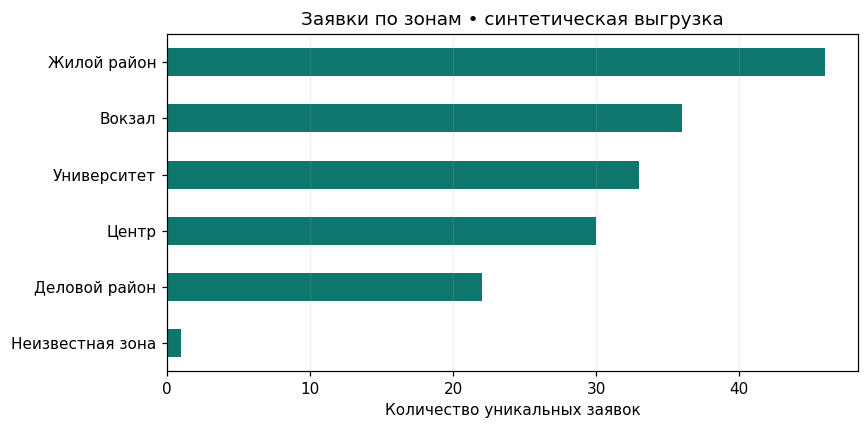

In [49]:
ax = zone_report.plot.barh(x="zone_report", y="requests", legend=False, color="#0F766E")
ax.invert_yaxis()
ax.set_title("Заявки по зонам • синтетическая выгрузка")
ax.set_xlabel("Количество уникальных заявок")
ax.set_ylabel("")
ax.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()

**Попробуйте, 4 минуты:** найдите зону с наибольшей долей отмен. Назовите одновременно процент и число заявок этой зоны. Почему 50% от 2 заявок и 50% от 100 заявок нельзя обсуждать одинаково уверенно?

Эта таблица не доказывает, что район или канал **вызывает** отмену. Мы пока описываем записи, а не проверяем причины.

In [50]:
# Ваш код здесь:
# zone_report.sort_values(...)[[...]].head(1)

## 12. Сохраняем CSV и JSON и читаем обратно

Отчёт полезен, когда его может открыть другой человек. Сохраним одинаковую небольшую таблицу в двух форматах.

- CSV удобен для таблиц и Excel. `index=False` не добавляет служебный индекс отдельным столбцом.
- JSON `orient="records"` — список объектов, по объекту на строку отчёта.
- `force_ascii=False` оставляет кириллицу читаемой в текстовом JSON.

Исходные файлы не перезаписываем: всё отправляется в отдельную папку `output/` текущего запуска.

In [51]:
# Округление — только для версии отчёта, исходные расчёты не меняем.
report_to_save = zone_report.round({"median_duration_min": 1, "cancel_pct": 1})
csv_path = OUTPUT_DIR / "zone_report.csv"
json_path = OUTPUT_DIR / "zone_report.json"
report_to_save.to_csv(csv_path, index=False, encoding="utf-8-sig")
report_to_save.to_json(json_path, orient="records", force_ascii=False, indent=2)
print("Сохранены:", csv_path.name, "и", json_path.name)

Сохранены: zone_report.csv и zone_report.json


In [52]:
csv_back = pd.read_csv(csv_path)
json_back = pd.read_json(json_path, orient="records")
display(csv_back.head(3))
display(json_back.head(3))

,zone_report,requests,completed_trips,cancelled_requests,payments_kzt,known_duration,median_duration_min,cancel_pct
0,Жилой район,46,39,7,84800.0,38,28.8,15.2
1,Вокзал,36,30,6,63700.0,29,28.8,16.7
2,Университет,33,27,6,60900.0,27,30.7,18.2


,zone_report,requests,completed_trips,cancelled_requests,payments_kzt,known_duration,median_duration_min,cancel_pct
0,Жилой район,46,39,7,84800,38,28.8,15.2
1,Вокзал,36,30,6,63700,29,28.8,16.7
2,Университет,33,27,6,60900,27,30.7,18.2


CSV не сохраняет все типы pandas. JSON тоже может прочитать `100.0` как целое `100`. Поэтому в учебной проверке сравним столбцы, размер и значения, разрешив различие числовых типов.

Это называется **round-trip**: записали → прочитали → убедились, что смысл не потерялся.

In [53]:
# У исходного отсортированного отчёта индекс мог быть не 0, 1, 2...
expected = report_to_save.reset_index(drop=True)
pd.testing.assert_frame_equal(expected, csv_back, check_dtype=False, atol=1e-8, rtol=1e-8)
pd.testing.assert_frame_equal(expected, json_back, check_dtype=False, atol=1e-8, rtol=1e-8)
print("CSV и JSON прочитаны без потерь значений.")

CSV и JSON прочитаны без потерь значений.


In [54]:
# Ищите эту папку в файловой панели Jupyter/Colab.
print("Результаты:", RUN_DIR.name + "/output/")
for file in OUTPUT_DIR.iterdir():
    print("-", file.name, "|", file.stat().st_size, "байт")

Результаты: week03_run_2yvjnivn/output/
- zone_report.json | 1384 байт
- zone_report.csv | 414 байт


**В Colab:** откройте панель Files слева, найдите показанную папку и скачайте `zone_report.csv` / `zone_report.json`. Диск временной сессии Colab может исчезнуть при её завершении, поэтому нужные результаты скачивайте заранее.

**В Jupyter:** файлы останутся в папке рядом с notebook. При следующем полном запуске создастся новая папка с другим окончанием.

## 13. Финальный вывод: пять предложений вместо «всё посчиталось»

Хороший вывод отвечает на вопрос и называет ограничения. Сначала соберём опорные числа.

In [55]:
total_requests = len(trips)
completed_count = int((trips["status"] == "completed").sum())
cancelled_count = int((trips["status"] == "cancelled").sum())
total_payments = completed["fare_kzt"].sum()
print("Уникальных заявок:", total_requests)
print("Завершено:", completed_count, "| Отменено:", cancelled_count)
print("Доля отмен, %:", round(cancelled_count / total_requests * 100, 1))
print("Сумма оплат, ₸:", total_payments)
print("Заявок без зоны в справочнике:", len(unmatched))

Уникальных заявок: 168
Завершено: 139 | Отменено: 29
Доля отмен, %: 17.3
Сумма оплат, ₸: 308400.0
Заявок без зоны в справочнике: 1


Заполните шаблон своими числами:

1. «В исходной выгрузке __ строк; после удаления __ полных повторов осталось __ уникальных заявок».
2. «Завершено __ заявок, отменено __; доля отмен среди всех заявок равна __%».
3. «Самая большая группа по числу заявок — __: __ заявок. Это описание этой выгрузки».
4. «У __ завершённых поездок неизвестна длительность, поэтому сводка длительности описывает __ измерений».
5. «У __ заявки не нашлось зоны. LEFT JOIN сохранил её и сумму оплаты. Все данные синтетические, поэтому переносить выводы на реальный город нельзя».

**Связь с AI/DS:** перед моделью прогноза отмен нам понадобятся дополнительные данные и отдельная проверка качества. Неизвестные зоны, повторы и неверные знаменатели способны испортить анализ ещё до выбора алгоритма.

## 14. Самостоятельная практика

**Сначала своя попытка.** Решения находятся в следующем разделе. Не изменяйте `raw_trips`, `trips`, `joined` ради отдельной задачи; создавайте новые переменные.

Задачи 1–4 закрепляют занятие 1, задачи 5–8 — занятие 2. Если застряли, сначала прочитайте подсказку и найдите похожий пример выше.

### Задача 1. Паспорт таблицы

Выведите число уникальных заявок, первые 4 строки только `trip_id`, `status`, `fare_kzt` и описательную статистику дистанции **завершённых** поездок.

**Подсказка:** `len`, выбор списка столбцов, `head`, `describe`.

In [56]:
# Ваше решение здесь.

### Задача 2. Неизвестные измерения

Сколько завершённых поездок имеют неизвестную длительность? Какой это процент от **всех завершённых поездок**? Не подставляйте ноль.

**Подсказка:** `completed["duration_min"].isna()`, `sum`, деление на `len(completed)`.

In [57]:
# Ваше решение здесь.

### Задача 3. Два условия

Найдите завершённые поездки из `app` с дистанцией не меньше 8 км. Покажите ID, канал, дистанцию и стоимость. Отсортируйте по стоимости по убыванию.

**Подсказка:** Начните с `completed`, используйте `&` и скобки.

In [58]:
# Ваше решение здесь.

### Задача 4. Типичная длительность

Для каждого канала, включая неизвестный, найдите число завершённых поездок, число известных длительностей и медианную длительность.

**Подсказка:** `groupby(..., dropna=False).agg(...)`; нужны и `size`, и `count`.

In [59]:
# Ваше решение здесь.

### Задача 5. Проверка ключей

Выведите заявки, у которых зона не нашлась, и их суммарную оплату. Затем проверьте, что после LEFT JOIN заявок столько же, сколько до него.

**Подсказка:** `_merge == "left_only"`, `sum`, `assert`.

In [60]:
# Ваше решение здесь.

### Задача 6. Суммы и количество

На `joined` отберите только завершённые поездки. Постройте сводку по `zone_report`: число поездок, сумма оплат, медианная стоимость. Убедитесь, что итоговая сумма совпадает с `completed["fare_kzt"].sum()`.

**Подсказка:** `groupby`, `agg`, `np.isclose`.

In [61]:
# Ваше решение здесь.

### Задача 7. Ещё один файл

Сохраните сводку из задачи 6 как `completed_by_zone.csv` в `OUTPUT_DIR`, без индекса. Прочитайте её и сравните число строк, список столбцов и сумму оплат.

**Подсказка:** `to_csv(index=False)`, `pd.read_csv`; если задачу 6 пропустили, сначала выполните её.

In [62]:
# Ваше решение здесь.

### Задача 8. Объяснение для команды

Напишите 4 предложения: что чаще встречается, какую метрику считали, какая проблема данных найдена, чего по этой таблице нельзя утверждать. Включите хотя бы одну конкретную цифру и её знаменатель.

**Подсказка:** Не используйте «доказали причину», «лучший район», «реальная статистика города».

In [63]:
# Ваше решение здесь.

## 15. Возможные решения

Открывайте после попытки. Разный код может быть правильным. Сравнивайте выбранные строки, знаменатели и сохранение сумм.

### Решение 1. Паспорт

In [64]:
print("Уникальных заявок:", len(trips))
display(trips[["trip_id", "status", "fare_kzt"]].head(4))
display(completed["distance_km"].describe().round(2))

Уникальных заявок: 168


,trip_id,status,fare_kzt
0,1001,cancelled,NaN
1,1002,completed,1100.0
2,1003,completed,3450.0
3,1004,completed,2650.0


count    139.00
mean       9.50
std        5.12
min        1.20
25%        5.15
50%       10.00
75%       13.60
max       18.50
Name: distance_km, dtype: float64

### Решение 2. Пропуски

In [65]:
missing_count = completed["duration_min"].isna().sum()
missing_pct = missing_count / len(completed) * 100
print("Неизвестных длительностей:", missing_count)
print("Доля среди завершённых, %:", round(missing_pct, 2))

Неизвестных длительностей: 2
Доля среди завершённых, %: 1.44


### Решение 3. Фильтр

In [66]:
answer3 = completed.loc[
    (completed["channel"] == "app") & (completed["distance_km"] >= 8),
    ["trip_id", "channel", "distance_km", "fare_kzt"],
].sort_values("fare_kzt", ascending=False)
print("Найдено:", len(answer3))
answer3.head()

Найдено: 60


,trip_id,channel,distance_km,fare_kzt
14,1015,app,18.5,3900.0
67,1068,app,18.0,3850.0
57,1058,app,17.8,3800.0
143,1144,app,18.0,3800.0
137,1138,app,18.0,3800.0


### Решение 4. Группы

In [67]:
answer4 = completed.groupby("channel", dropna=False).agg(
    trips=("trip_id", "size"),
    known_duration=("duration_min", "count"),
    median_duration_min=("duration_min", "median"),
)
answer4.round(1)

,trips,known_duration,median_duration_min
channel,,,
app,98,97,31.6
phone,25,24,28.8
web,13,13,24.7
NaN,3,3,54.7


### Решение 5. Неизвестная зона

In [68]:
answer5 = joined.loc[joined["_merge"] == "left_only"]
display(answer5[["trip_id", "zone_id", "fare_kzt"]])
print("Сумма оплат без найденной зоны, ₸:", answer5["fare_kzt"].sum())
assert len(joined) == len(trips)

Сумма оплат без найденной зоны, ₸: 2700.0


,trip_id,zone_id,fare_kzt
92,1093,Z99,2700.0


### Решение 6. Денежная сводка

In [69]:
answer6 = joined.loc[joined["status"] == "completed"].groupby(
    "zone_report", as_index=False
).agg(
    completed_trips=("trip_id", "size"),
    payments_kzt=("fare_kzt", "sum"),
    median_fare_kzt=("fare_kzt", "median"),
)
assert np.isclose(answer6["payments_kzt"].sum(), completed["fare_kzt"].sum())
answer6.sort_values("payments_kzt", ascending=False)

,zone_report,completed_trips,payments_kzt,median_fare_kzt
2,Жилой район,39,84800.0,2250.0
5,Центр,26,64750.0,2400.0
0,Вокзал,30,63700.0,1925.0
4,Университет,27,60900.0,2200.0
1,Деловой район,16,31550.0,1725.0
3,Неизвестная зона,1,2700.0,2700.0


### Решение 7. Экспорт

In [70]:
answer7_path = OUTPUT_DIR / "completed_by_zone.csv"
answer6.to_csv(answer7_path, index=False, encoding="utf-8-sig")
answer7_back = pd.read_csv(answer7_path)
assert len(answer7_back) == len(answer6)
assert answer7_back.columns.tolist() == answer6.columns.tolist()
assert np.isclose(answer7_back["payments_kzt"].sum(), answer6["payments_kzt"].sum())
print("Сохранён и проверен", answer7_path.name)

Сохранён и проверен completed_by_zone.csv


### Решение 8. Короткий вывод

In [71]:
top_channel = trips["channel"].fillna("unknown").value_counts().index[0]
top_count = int(trips["channel"].fillna("unknown").value_counts().iloc[0])
print(f"В учебной выгрузке канал {top_channel} встречается в {top_count} из {len(trips)} заявок.")
print(f"Доля отмен среди всех заявок — {cancelled_count / len(trips):.1%}.")
print(f"После LEFT JOIN {len(unmatched)} заявка не получила название зоны, но сохранилась в отчёте.")
print("По синтетической выгрузке нельзя оценивать реальный трафик или причины отмен в городе.")

В учебной выгрузке канал app встречается в 116 из 168 заявок.
Доля отмен среди всех заявок — 17.3%.
После LEFT JOIN 1 заявка не получила название зоны, но сохранилась в отчёте.
По синтетической выгрузке нельзя оценивать реальный трафик или причины отмен в городе.


## 16. Бонус: время, сводная таблица и ещё один график

**Не обязателен для двух занятий.** Это следующий маленький шаг, если основной маршрут уже понятен.

`pivot_table` — сводка сразу по двум категориям: зоны по строкам, статусы по столбцам. Заполнение нулём уместно для **числа заявок** в отсутствующей комбинации внутри этой фиксированной выгрузки. Это не разрешение заменять нулём неизвестную длительность.

In [72]:
status_pivot = joined.pivot_table(
    index="zone_report", columns="status", values="trip_id",
    aggfunc="size", fill_value=0,
)
status_pivot

status,cancelled,completed
zone_report,,
Вокзал,6,30
Деловой район,6,16
Жилой район,7,39
Неизвестная зона,0,1
Университет,6,27
Центр,4,26


### Сколько заявок в каждый час?

Группируем по часу создания заявки. Это смешивает разные дни: точка «8» включает заявки в 08:00–08:59 за весь учебный период.

Генератор специально распределил заявки регулярно: в данных **нет естественного городского суточного профиля**. Ровный график — свойство учебной конструкции, не открытие о городе. Для поиска реальных пиков потребовались бы реальные наблюдения и проверка полноты выгрузки.

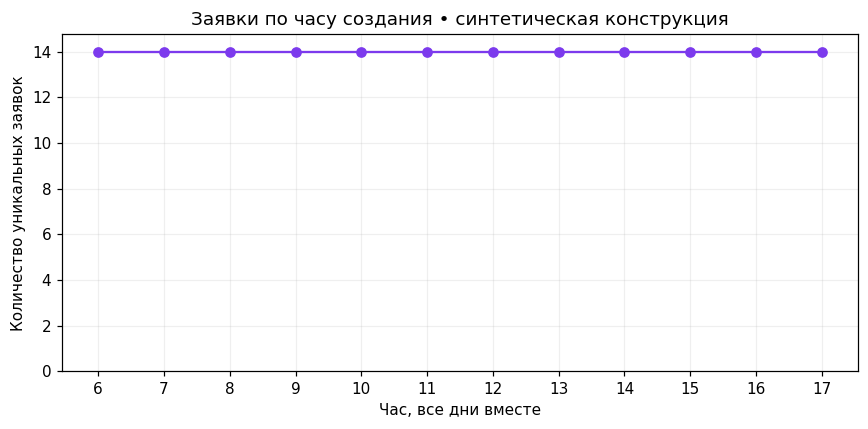

In [73]:
requests_by_hour = trips.groupby("request_hour").size()
ax = requests_by_hour.plot(marker="o", color="#7C3AED")
ax.set_title("Заявки по часу создания • синтетическая конструкция")
ax.set_xlabel("Час, все дни вместе")
ax.set_ylabel("Количество уникальных заявок")
ax.set_xticks(requests_by_hour.index)
ax.set_ylim(bottom=0)
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

### Мини-проект на 15–20 минут

Сравните заявки, созданные **до 12:00**, с заявками **с 12:00**.
1. Создайте признак `period` на копии `joined` (подсказка: `np.where`).
2. Для каждой группы найдите число заявок, число отмен и долю отмен.
3. Убедитесь, что общее число заявок сохранилось.
4. Напишите два предложения, не объясняя различия выдуманными причинами.

Пример результата может быть любым по форме, но должен содержать размер каждой группы и знаменатель доли. Решение ниже — для самопроверки.

In [74]:
# Ваша попытка, до просмотра следующей ячейки.

In [75]:
bonus = joined.copy()
bonus["period"] = np.where(bonus["request_hour"] < 12, "До 12:00", "С 12:00")
bonus_report = bonus.groupby("period").agg(
    requests=("trip_id", "size"), cancellations=("is_cancelled", "sum")
)
bonus_report["cancel_pct"] = bonus_report["cancellations"] / bonus_report["requests"] * 100
assert bonus_report["requests"].sum() == len(trips)
bonus_report.round(1)

,requests,cancellations,cancel_pct
period,,,
До 12:00,84,18,21.4
С 12:00,84,11,13.1


## Чек-лист и частые ошибки

- [ ] Объясняю, что означает одна строка и почему заявка не всегда поездка.
- [ ] Сохраняю исходник и проверяю, прежде чем удалять повторы.
- [ ] Отличаю `loc` от `iloc`, столбец от таблицы.
- [ ] Пишу маску со скобками и `&`, учитываю пропуски.
- [ ] Понимаю `size`, `count`, `mean`, `median` и знаменатель доли.
- [ ] Читаю CSV/JSON и преобразую строку в дату.
- [ ] Объединяю по ключу, проверяю число строк и неизвестные пары.
- [ ] Сохраняю отчёт без лишнего индекса и читаю его обратно.
- [ ] Подписываю график и не делаю выводы за пределами данных.

| Если видите | Сначала проверьте |
|---|---|
| `NameError` | Выполнена ли ячейка выше, где создаётся переменная? |
| `KeyError` | Имя столбца, регистр, содержимое `.columns.tolist()` |
| «truth value of a Series is ambiguous» | Не использовали ли `and` вместо `&`, хватает ли скобок? |
| `MergeError` | Уникален ли ключ в справочнике? Не убирайте `validate`, чтобы спрятать проблему |
| `AssertionError` | Какая проверка сработала и на каком шаге изменились строки/суммы? |
| Лишний столбец `Unnamed: 0` | Не сохранили ли CSV с индексом? Нужен `index=False` |
| Дата осталась `object` | Выполнен ли `pd.to_datetime`? |

Если случайно изменили ключевую переменную, проще сделать **Restart Kernel → Run All**, чем исправлять состояние по памяти.

## Источники, происхождение и воспроизводимость

- Практика продолжает [Titanic Week 02](https://github.com/AssylbekGizatov/tech-orda-course-by-assylbek-additional-materials/blob/main/week_02_python_numpy/practice/02_titanic_pandas_numpy_descriptive_practice.ipynb) и соответствует [плану Week 03](https://github.com/AssylbekGizatov/tech-orda-course-by-assylbek-additional-materials/blob/main/week_03_pandas_files/README.md).
- `trips.csv` и `zones.json` созданы специально для этого практикума. Люди, районы и поездки не представляют реальных субъектов. Никаких персональных данных в наборе нет.
- 7 условных дней: 5–11 октября 2026; 24 заявки в день, 168 уникальных ID. Копии двух строк добавлены специально для проверки качества.
- Фиксированный снимок данных встроен в notebook: повторный запуск не генерирует новую случайную выборку. Имена рабочих папок меняются, содержимое учебных данных — нет.
- Пропуски, неизвестная зона и повторы — запланированные учебные ситуации. Это не оценка качества данных какого-либо действующего сервиса.
- Проверенная среда: Python 3.12, pandas 2.2.3, NumPy 2.1.3, matplotlib 3.9.2. В других версиях оформление вывода может немного отличаться.

Документация:
- [pandas: вводные учебники](https://pandas.pydata.org/docs/getting_started/intro_tutorials/index.html)
- [Выбор строк и столбцов](https://pandas.pydata.org/docs/user_guide/indexing.html)
- [GroupBy](https://pandas.pydata.org/docs/user_guide/groupby.html)
- [Объединение таблиц](https://pandas.pydata.org/docs/user_guide/merging.html)
- [CSV и JSON](https://pandas.pydata.org/docs/user_guide/io.html)

**Главная мысль недели:** сначала поймите и проверьте данные, затем считайте и объясняйте. Сложность анализа определяется не длиной команды, а тем, насколько верно она отвечает на вопрос.